# Etapa 2 — Inferencia: Granger condicional (H2) y poder predictivo del ONI pre-siembra (H1)

| Sección | Pregunta | Métodos | Clase |
|---|---|---|---|
| 1 | ¿El Granger inverso (lluvia → Pacífico) desaparece al controlar? | VAR, Granger condicional, SAM e IOD | 8, 11 |
| 2 | ¿Cuánto vale la CCF una vez sacada la autocorrelación? | preblanqueo AR | 6, 11 |
| 3 | **H1**: ¿el ONI de jul–sep aporta información sobre el rinde? | modelos anidados, F, permutación, Holm | 8, 11 |
| 4 | ¿Se sostiene a escala departamental? | panel, errores agrupados por año | — |
| 5 | ¿La lluvia es el canal? | mediación | — |

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.api import VAR
from statsmodels.tsa.ar_model import AutoReg, ar_select_order

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from utils_ts import (COLOR, CULTIVO_COLOR, CULTIVO_NOMBRE, adf_kpss, anomalias, ccf, estilo,
                      oni_campanias, rindes, tendencia, anomalia_relativa)

warnings.filterwarnings("ignore")
estilo()
PROC, FIG, RES = RAIZ / "data" / "processed", RAIZ / os.environ.get("FIG_DIR", "figures"), RAIZ / "results"
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True, parents=True)
enso = pd.read_parquet(PROC / "enso_mensual.parquet")
clima = pd.read_parquet(PROC / "clima_pampeano_mensual.parquet")
rend = pd.read_parquet(PROC / "rendimientos_anuales.parquet")
camp = pd.read_parquet(PROC / "campanias.parquet")
deptos = pd.read_parquet(PROC / "rendimientos_departamentos.parquet")
resultados = {}

## 1. Granger en un VAR mensual: incondicional y condicional

En la Etapa 1 el test de Granger dio significativo **en las dos direcciones**. La lluvia de la Pampa
no puede calentar el Pacífico, así que algo comparten las dos series. Probamos tres candidatos a
tercera variable (Clase 8: "fumar" detrás de "encendedor" y "cáncer"):
- **SAM** (Modo Anular del Sur) e **IOD** (Dipolo del Índico): modulan la lluvia pampeana y se correlacionan con el ENSO.
- **SOI**: la componente atmosférica del ENSO (presión Tahití − Darwin).
- **WWV** (Warm Water Volume, NOAA PMEL): el calor acumulado *bajo la superficie* del Pacífico ecuatorial.
  Es el precursor clásico del ENSO, porque se carga meses antes de que el Niño 3.4 se caliente.

Si al incluir un candidato en el VAR desaparece el Granger inverso y el directo sigue en pie, ese candidato es el confusor.

In [2]:
m = pd.concat([enso[["n34_anom", "sam", "iod", "soi", "wwv"]], clima["precip_z"]], axis=1).loc["1981":"2025"].dropna()
print(f"meses: {len(m)} ({m.index[0]:%Y-%m} a {m.index[-1]:%Y-%m})")
print(pd.DataFrame({c: adf_kpss(m[c]) for c in m}).T.to_string())
print("\ncorrelaciones contemporáneas:")
print(m.corr().round(2).to_string())

meses: 540 (1981-01 a 2025-12)
            n p_ADF p_KPSS      decisión
n34_anom  540   0.0    0.1  estacionaria
sam       540   0.0   0.03    indefinida
iod       540   0.0   0.01    indefinida
soi       540   0.0  0.062  estacionaria
wwv       540   0.0    0.1  estacionaria
precip_z  540   0.0    0.1  estacionaria

correlaciones contemporáneas:
          n34_anom   sam   iod   soi   wwv  precip_z
n34_anom      1.00 -0.13  0.41 -0.72  0.12      0.21
sam          -0.13  1.00  0.03  0.15 -0.07      0.03
iod           0.41  0.03  1.00 -0.22  0.15      0.07
soi          -0.72  0.15 -0.22  1.00 -0.04     -0.14
wwv           0.12 -0.07  0.15 -0.04  1.00      0.01
precip_z      0.21  0.03  0.07 -0.14  0.01      1.00


In [3]:
def granger_var(datos: pd.DataFrame, causa: str, efecto: str, p: int) -> float:
    res = VAR(datos).fit(p)
    return res.test_causality(efecto, [causa], kind="f").pvalue


sel2 = VAR(m[["n34_anom", "precip_z"]]).select_order(12)
print(f"orden VAR bivariado: AIC p={sel2.selected_orders['aic']}, BIC p={sel2.selected_orders['bic']} → usamos p = 2, 3 y 4")

base = ["n34_anom", "precip_z"]
modelos = {"bivariado": base, "+ SAM": base + ["sam"], "+ IOD": base + ["iod"], "+ SAM + IOD": base + ["sam", "iod"],
           "+ SOI": base + ["soi"], "+ WWV": base + ["wwv"], "+ WWV + SAM + IOD": base + ["wwv", "sam", "iod"]}
filas = []
for nombre, cols in modelos.items():
    for q in (2, 3, 4):
        filas.append({"VAR": nombre, "lags": q,
                      "Niño3.4 → lluvia": granger_var(m[cols], "n34_anom", "precip_z", q),
                      "lluvia → Niño3.4": granger_var(m[cols], "precip_z", "n34_anom", q)})
g = pd.DataFrame(filas)
print(g.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nWWV → Niño3.4 (VAR(3)):", f"{granger_var(m[['n34_anom', 'wwv']], 'wwv', 'n34_anom', 3):.1e}",
      "· WWV → lluvia:", f"{granger_var(m[['precip_z', 'wwv']], 'wwv', 'precip_z', 3):.3f}")

orden VAR bivariado: AIC p=4, BIC p=2 → usamos p = 2, 3 y 4
              VAR  lags  Niño3.4 → lluvia  lluvia → Niño3.4
        bivariado     2            0.0001            0.0075
        bivariado     3            0.0003            0.0174
        bivariado     4            0.0007            0.0150
            + SAM     2            0.0002            0.0076
            + SAM     3            0.0004            0.0203
            + SAM     4            0.0009            0.0173
            + IOD     2            0.0008            0.0093
            + IOD     3            0.0017            0.0254
            + IOD     4            0.0040            0.0170
      + SAM + IOD     2            0.0013            0.0098
      + SAM + IOD     3            0.0024            0.0295
      + SAM + IOD     4            0.0046            0.0195
            + SOI     2            0.0331            0.0047
            + SOI     3            0.0317            0.0132
            + SOI     4            0.043

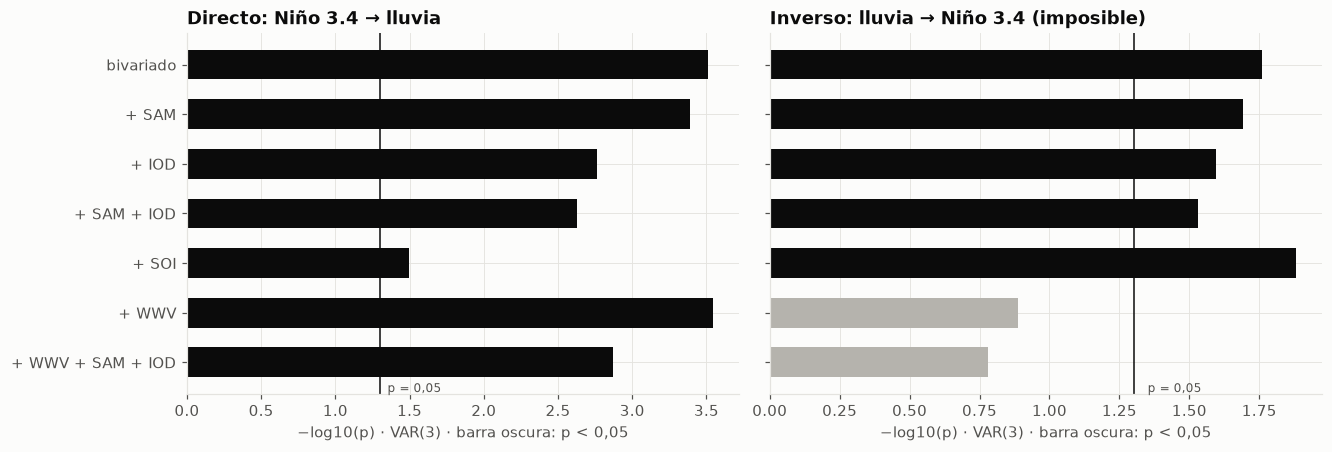

In [4]:
piv = g.pivot(index="VAR", columns="lags").loc[list(modelos)]
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, tit in [(axs[0], "Niño3.4 → lluvia", "Directo: Niño 3.4 → lluvia"),
                     (axs[1], "lluvia → Niño3.4", "Inverso: lluvia → Niño 3.4 (imposible)")]:
    v = -np.log10(piv[col][3])
    colores = [COLOR["tinta"] if p < 0.05 else COLOR["neutral"] for p in piv[col][3]]
    ax.barh(range(len(v)), v, color=colores, height=0.6)
    ax.axvline(-np.log10(0.05), color=COLOR["tinta"], lw=1)
    ax.text(-np.log10(0.05) + 0.05, len(v) - 0.4, "p = 0,05", fontsize=8, color=COLOR["tinta2"])
    ax.set_yticks(range(len(v)), piv.index)
    ax.set_title(tit)
    ax.set_xlabel("−log10(p) · VAR(3) · barra oscura: p < 0,05")
axs[0].invert_yaxis()                      # eje y compartido: invertir una sola vez
fig.savefig(FIG / "07a_granger_condicional.png")
plt.show()

**¿Y si el Granger inverso viene de la estacionalidad de la varianza?** La teleconexión ENSO–lluvia es
fuerte en primavera y débil en invierno. En ese caso, un VAR lineal con coeficientes constantes queda
mal especificado. Lo chequeamos de dos formas: con errores robustos a heterocedasticidad (HC3) en la
regresión de Granger inversa, y con un **placebo de 1.000 permutaciones por bloques de 12 meses** de la
lluvia, que conserva su autocorrelación y destruye la relación temporal con el Pacífico.

In [5]:
def f_inverso(df: pd.DataFrame, p: int, robusto: bool = False) -> tuple[float, float]:
    """F (o Wald robusto) de los lags de lluvia en la ecuación del Niño 3.4."""
    X = pd.concat({f"n34_l{k}": df.n34_anom.shift(k) for k in range(1, p + 1)} |
                  {f"pr_l{k}": df.precip_z.shift(k) for k in range(1, p + 1)}, axis=1)
    d = pd.concat([df.n34_anom, X], axis=1).dropna()
    res = sm.OLS(d.n34_anom, sm.add_constant(d.drop(columns="n34_anom"))).fit(cov_type="HC3" if robusto else "nonrobust")
    r = res.f_test(" = 0, ".join(f"pr_l{k}" for k in range(1, p + 1)) + " = 0")
    return float(np.squeeze(r.fvalue)), float(r.pvalue)


p_ref = 3
F_obs, p_cl = f_inverso(m, p_ref)
_, p_hc3 = f_inverso(m, p_ref, robusto=True)
rng = np.random.default_rng(42)
bloques = [m.precip_z.iloc[i:i + 12].to_numpy() for i in range(0, len(m), 12)]
F_perm = []
for _ in range(1000):
    orden = rng.permutation(len(bloques))
    pr = np.concatenate([bloques[i] for i in orden])[:len(m)]
    F_perm.append(f_inverso(m.assign(precip_z=pr), p_ref)[0])
p_perm = (1 + np.sum(np.array(F_perm) >= F_obs)) / (1 + len(F_perm))
print(f"Granger inverso lluvia → Niño3.4 con {p_ref} lags:  F = {F_obs:.2f}")
print(f"  p clásico = {p_cl:.4f}   p HC3 = {p_hc3:.4f}   p permutación por bloques = {p_perm:.4f}")
F_dir, p_dir = f_inverso(m.rename(columns={"n34_anom": "precip_z", "precip_z": "n34_anom"}), p_ref)
print(f"Granger directo Niño3.4 → lluvia (misma regresión): F = {F_dir:.2f}, p = {p_dir:.2e}")
resultados["granger"] = {"tabla": g.round(5).to_dict("records"), "p_inverso_clasico": p_cl, "p_inverso_HC3": p_hc3,
                         "p_inverso_permutacion": p_perm, "p_directo": p_dir}

Granger inverso lluvia → Niño3.4 con 3 lags:  F = 3.40
  p clásico = 0.0177   p HC3 = 0.0130   p permutación por bloques = 0.0150
Granger directo Niño3.4 → lluvia (misma regresión): F = 6.30, p = 3.32e-04


## 2. CCF preblanqueada (Clases 6 y 11)

Las bandas ±1,96/√n de la CCF suponen ruido blanco, y el Niño 3.4 tiene r₁ ≈ 0,95. Por eso preblanqueamos:
ajustamos un AR(p) al Niño 3.4, nos quedamos con sus innovaciones y aplicamos **el mismo filtro** a la lluvia.
Ese filtro es un FIR (Clase 9) con coeficientes [1, −φ₁, …, −φₚ]. Lo que queda es la respuesta de la lluvia a las
*sorpresas* del Pacífico.

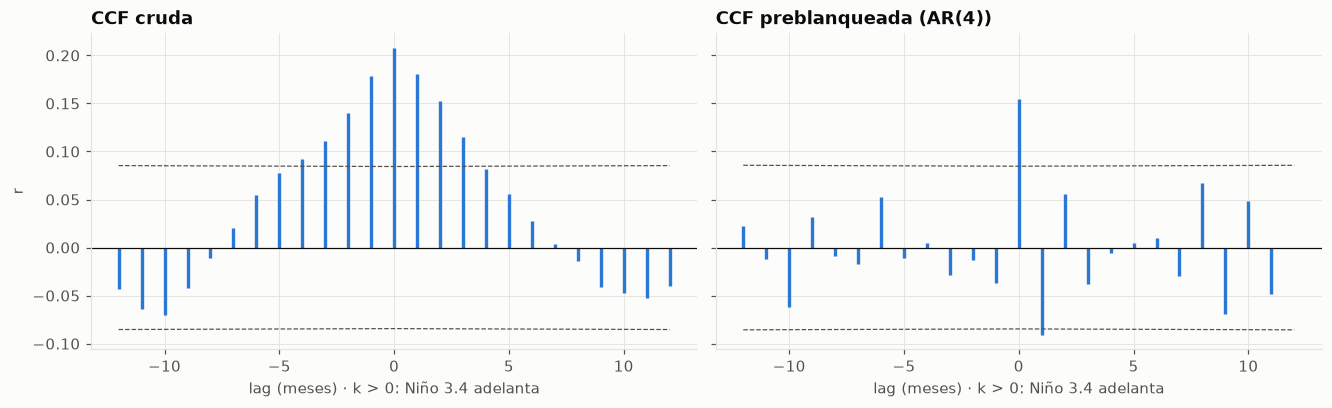

lag          -3     -2     -1     0      1      2      3      4 
r        -0.028 -0.013 -0.037  0.154 -0.091  0.056 -0.038 -0.006
umbral95  0.085  0.085  0.085  0.085  0.085  0.085  0.085  0.085


In [6]:
x = m.n34_anom
p_ar = max(ar_select_order(x.to_numpy(), maxlag=24, ic="bic").ar_lags or [1])
phi = AutoReg(x.to_numpy(), lags=p_ar, trend="c").fit().params[1:]
h = np.r_[1, -phi]


def filtrar(s: pd.Series) -> pd.Series:
    return pd.Series(np.convolve(s.to_numpy() - s.mean(), h, mode="full")[:len(s)], index=s.index).iloc[p_ar:]


cc_raw = ccf(m.n34_anom, m.precip_z, 12)
cc_pw = ccf(filtrar(m.n34_anom), filtrar(m.precip_z), 12)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, cc, tit in [(axs[0], cc_raw, "CCF cruda"), (axs[1], cc_pw, f"CCF preblanqueada (AR({p_ar}))")]:
    ax.vlines(cc.lag, 0, cc.r, color=COLOR["serie"], lw=2.2)
    ax.plot(cc.lag, cc.umbral95, color=COLOR["tinta2"], lw=0.8, ls="--")
    ax.plot(cc.lag, -cc.umbral95, color=COLOR["tinta2"], lw=0.8, ls="--")
    ax.axhline(0, color=COLOR["tinta"], lw=0.8)
    ax.set_title(tit)
    ax.set_xlabel("lag (meses) · k > 0: Niño 3.4 adelanta")
axs[0].set_ylabel("r")
fig.savefig(FIG / "07_ccf_preblanqueada.png")
plt.show()
print(cc_pw.set_index("lag").loc[-3:4, ["r", "umbral95"]].round(3).T.to_string())

## 3. H1: ¿el ONI de jul–sep (antes de la siembra) predice la anomalía de rinde?

Comparamos dos modelos anidados, que es la lógica de Granger con el ONI medido *antes* de la campaña:

- restringido: anom_t = α + φ·anom_{t−1} + ε
- completo:    anom_t = α + φ·anom_{t−1} + β·ONI_JAS_t + ε

Testeamos H0: β = 0 con un test F. Calculamos además un p-valor **por permutación** (10.000 reordenamientos del ONI),
que no supone normalidad, y aplicamos **corrección de Holm** sobre las dos hipótesis primarias (soja y maíz).
El trigo se reporta aparte, como contraste.

In [7]:
Y = rindes(rend)
A = anomalias(Y)
O = oni_campanias(camp)


def h1(anom: pd.Series, oni: pd.Series, n_perm: int = 10000, semilla: int = 0) -> dict:
    d = pd.DataFrame({"y": anom, "y1": anom.shift(1), "oni": oni}).dropna()
    r0 = smf.ols("y ~ y1", d).fit()
    r1 = smf.ols("y ~ y1 + oni", d).fit()
    F, pF, _ = r1.compare_f_test(r0)
    rng = np.random.default_rng(semilla)
    t_obs = r1.tvalues["oni"]
    X = sm.add_constant(d[["y1", "oni"]]).to_numpy()
    t_perm = np.empty(n_perm)
    for i in range(n_perm):
        Xp = X.copy()
        Xp[:, 2] = rng.permutation(Xp[:, 2])
        b, *_ = np.linalg.lstsq(Xp, d.y.to_numpy(), rcond=None)
        e = d.y.to_numpy() - Xp @ b
        s2 = e @ e / (len(e) - 3)
        t_perm[i] = b[2] / np.sqrt(s2 * np.linalg.inv(Xp.T @ Xp)[2, 2])
    return {"n": int(r1.nobs), "beta_%/°C": r1.params["oni"], "IC95": tuple(r1.conf_int().loc["oni"].round(2)),
            "F": F, "p_F": pF, "p_perm_1cola": (1 + np.sum(t_perm >= t_obs)) / (1 + n_perm),
            "R2_restr": r0.rsquared, "R2_compl": r1.rsquared, "phi_y1": r1.params["y1"], "p_phi": r1.pvalues["y1"]}


tab_h1 = pd.DataFrame({c: h1(A[c], O["oni_JAS_0"]) for c in ["soja", "maiz", "trigo"]}).T
tab_h1["p_Holm"] = np.nan
tab_h1.loc[["soja", "maiz"], "p_Holm"] = multipletests(tab_h1.loc[["soja", "maiz"], "p_F"].astype(float), method="holm")[1]
print(tab_h1.to_string(float_format=lambda v: f"{v:.4f}"))
resultados["h1"] = {c: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in fila.items()}
                    for c, fila in tab_h1.iterrows()}

        n beta_%/°C           IC95       F    p_F p_perm_1cola R2_restr R2_compl  phi_y1  p_phi  p_Holm
soja   54    9.1027  (3.53, 14.67) 10.7710 0.0019       0.0012   0.0198   0.1907 -0.0097 0.9416  0.0019
maiz   54    9.3218  (4.51, 14.13) 15.1505 0.0003       0.0002   0.0120   0.2383  0.0973 0.4684  0.0006
trigo  54    0.1561  (-4.93, 5.24)  0.0038 0.9511       0.4796   0.0000   0.0001  0.0092 0.9503     NaN


### Sensibilidad: otro trimestre, otro filtro de tendencia, otra definición de rinde

In [8]:
sens = []
variantes = {
    "base (pampeana, LOWESS, ONI JAS)": (A, "oni_JAS_0"),
    "ONI JJA": (A, "oni_JJA_0"),
    "ONI SON": (A, "oni_SON_0"),
    "ONI DJF (dentro del ciclo)": (A, "oni_DJF_1"),
    "tendencia MA9": (anomalias(Y, "ma"), "oni_JAS_0"),
    "tendencia lineal": (anomalias(Y, "lineal"), "oni_JAS_0"),
    "rinde nacional": (anomalias(rindes(rend, "nacional")), "oni_JAS_0"),
    "rinde s/ sembrada": (anomalias(rindes(rend, columna="rend_sembrada_kgha")), "oni_JAS_0"),
}
for nombre, (AA, col) in variantes.items():
    fila = {"variante": nombre}
    for c in ["soja", "maiz"]:
        r = h1(AA[c], O[col], n_perm=0)
        fila[f"β {c}"] = r["beta_%/°C"]
        fila[f"p {c}"] = r["p_F"]
    sens.append(fila)
sens = pd.DataFrame(sens)
print(sens.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
resultados["h1_sensibilidad"] = sens.round(4).to_dict("records")

                        variante  β soja  p soja  β maiz  p maiz
base (pampeana, LOWESS, ONI JAS)   9.103   0.002   9.322   0.000
                         ONI JJA  10.894   0.001  10.796   0.000
                         ONI SON   6.504   0.002   6.753   0.000
      ONI DJF (dentro del ciclo)   5.697   0.003   5.413   0.001
                   tendencia MA9   8.703   0.003   9.457   0.000
                tendencia lineal   9.778   0.001  11.307   0.000
                  rinde nacional   7.451   0.006   8.483   0.001
               rinde s/ sembrada   9.204   0.003  11.133   0.001


## 4. Panel departamental: ¿la señal es general o la arrastran unos pocos partidos?

Usamos los departamentos pampeanos con ≥ 40 campañas de soja (o maíz) y con superficie relevante. Ojo: el ONI
es **el mismo para todos los departamentos en un año dado**, así que la información efectiva sigue siendo de ~50 años,
no de 50 × N. Por eso los errores estándar se **agrupan por campaña**. Si no se agrupan, el p-valor queda
artificialmente chico.

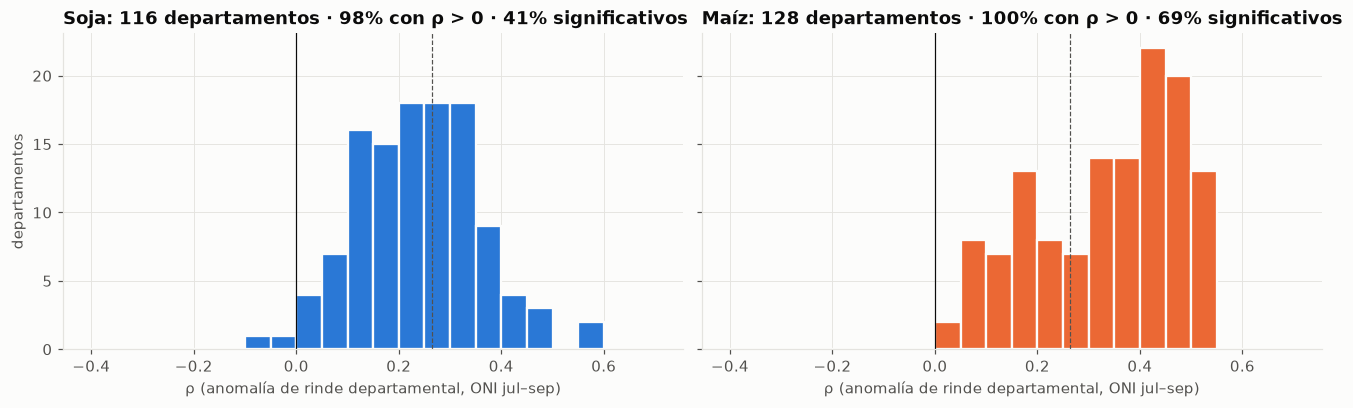

soja: β = 6.48 %/°C · p agrupado por año = 0.0001 · p ingenuo (sin agrupar) = 2.71e-62 · obs = 5754
maiz: β = 9.21 %/°C · p agrupado por año = 0.0001 · p ingenuo (sin agrupar) = 1.41e-137 · obs = 7014


In [9]:
dep = deptos[deptos.provincia_id.isin(["06", "14", "82", "30", "42"]) & deptos.anio.between(1970, 2024)].copy()
dep["rend"] = 1000 * dep.produccion_tm / dep.superficie_cosechada_ha.replace(0, np.nan)
panel, corrs = [], []
for c in ["soja", "maiz"]:
    d = dep[dep.cultivo == c]
    for did, g_ in d.groupby("departamento_id"):
        s = g_.set_index("anio")["rend"].dropna()
        if len(s) < 40 or g_.superficie_sembrada_ha.median() < 5000:
            continue
        an = anomalia_relativa(s, tendencia(s, "lowess")).clip(-100, 150)
        panel.append(pd.DataFrame({"cultivo": c, "depto": did, "campania": an.index, "anom": an.values}))
        oo = O.loc[an.index, "oni_JAS_0"]
        corrs.append({"cultivo": c, "depto": did, "provincia": g_.provincia.iloc[0], "n": len(an),
                      "rho": stats.spearmanr(an, oo).statistic})
panel = pd.concat(panel).merge(O[["oni_JAS_0"]].reset_index(), on="campania")
corrs = pd.DataFrame(corrs)
umb = 1.96 / np.sqrt(corrs.n.median())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, c in zip(axs, ["soja", "maiz"]):
    v = corrs[corrs.cultivo == c].rho
    ax.hist(v, bins=np.arange(-0.4, 0.75, 0.05), color=CULTIVO_COLOR[c], edgecolor=COLOR["fondo"], lw=1.5)
    ax.axvline(0, color=COLOR["tinta"], lw=0.8)
    ax.axvline(umb, color=COLOR["tinta2"], lw=0.8, ls="--")
    ax.set_title(f"{CULTIVO_NOMBRE[c]}: {len(v)} departamentos · {np.mean(v > 0):.0%} con ρ > 0 · {np.mean(v > umb):.0%} significativos")
    ax.set_xlabel("ρ (anomalía de rinde departamental, ONI jul–sep)")
axs[0].set_ylabel("departamentos")
fig.savefig(FIG / "08_panel_departamentos.png")
plt.show()

for c in ["soja", "maiz"]:
    d = panel[panel.cultivo == c]
    r_fe = smf.ols("anom ~ oni_JAS_0 + C(depto)", d).fit(cov_type="cluster", cov_kwds={"groups": d.campania})
    r_ing = smf.ols("anom ~ oni_JAS_0 + C(depto)", d).fit()
    print(f"{c}: β = {r_fe.params['oni_JAS_0']:.2f} %/°C · p agrupado por año = {r_fe.pvalues['oni_JAS_0']:.4f} "
          f"· p ingenuo (sin agrupar) = {r_ing.pvalues['oni_JAS_0']:.2e} · obs = {int(r_fe.nobs)}")
    resultados.setdefault("panel", {})[c] = {"beta": r_fe.params["oni_JAS_0"], "p_cluster": r_fe.pvalues["oni_JAS_0"],
                                             "p_naive": r_ing.pvalues["oni_JAS_0"], "n_deptos": int(d.depto.nunique()),
                                             "frac_pos": float(np.mean(corrs[corrs.cultivo == c].rho > 0))}

## 5. Mediación: ¿cuánto del efecto ONI → rinde pasa por la lluvia?

Campañas 1981/82–2024/25 (es lo que cubre NASA POWER). Si β_ONI cae fuerte al agregar la lluvia de la ventana
crítica, la lluvia es el canal principal. Es un análisis de mediación simple al estilo Baron-Kenny, con
bootstrap del efecto indirecto.

In [10]:
ventana_lluvia = {"soja": (12, 3), "maiz": (11, 2)}


def lluvia(anio, ini, fin):
    a0 = pd.Timestamp(anio, ini, 1)
    a1 = pd.Timestamp(anio + (fin < ini), fin, 1)
    s = clima.loc[a0:a1, "precip_mm"]
    return s.sum() if len(s) == (a1.year - a0.year) * 12 + a1.month - a0.month + 1 else np.nan


med = {}
for c, (ini, fin) in ventana_lluvia.items():
    d = pd.DataFrame({"anom": A[c], "oni": O["oni_JAS_0"]})
    d["lluvia"] = [lluvia(a, ini, fin) for a in d.index]
    d = d.dropna()
    d["lluvia"] = (d.lluvia - d.lluvia.mean()) / d.lluvia.std()
    tot = smf.ols("anom ~ oni", d).fit()
    a_ = smf.ols("lluvia ~ oni", d).fit()
    dir_ = smf.ols("anom ~ oni + lluvia", d).fit()
    rng = np.random.default_rng(1)
    ind = []
    for _ in range(5000):
        b = d.sample(len(d), replace=True, random_state=rng.integers(1e9))
        ind.append(smf.ols("lluvia ~ oni", b).fit().params["oni"] * smf.ols("anom ~ oni + lluvia", b).fit().params["lluvia"])
    med[c] = {"n": len(d), "efecto_total": tot.params["oni"], "p_total": tot.pvalues["oni"],
              "efecto_directo": dir_.params["oni"], "p_directo": dir_.pvalues["oni"],
              "indirecto": a_.params["oni"] * dir_.params["lluvia"], "IC95_ind": tuple(np.percentile(ind, [2.5, 97.5]).round(2)),
              "prop_mediada": a_.params["oni"] * dir_.params["lluvia"] / tot.params["oni"]}
print(pd.DataFrame(med).T.to_string(float_format=lambda v: f"{v:.3f}"))
resultados["mediacion"] = {c: {k: (float(v) if not isinstance(v, tuple) else v) for k, v in r.items()} for c, r in med.items()}

       n efecto_total p_total efecto_directo p_directo indirecto      IC95_ind prop_mediada
soja  44        7.335   0.009          2.708     0.231     4.627  (2.07, 8.03)        0.631
maiz  44        8.181   0.000          4.089     0.055     4.092  (1.23, 7.77)        0.500


In [11]:
(RES / "etapa2.json").write_text(json.dumps(resultados, indent=2, default=float, ensure_ascii=False))
print("guardado results/etapa2.json")

guardado results/etapa2.json


## 6. Conclusiones de la Etapa 2

**H2 (mecanismo mensual)**
- El Granger directo (Niño 3.4 → lluvia pampeana) es robusto. Da p ≤ 0,005 en todas las especificaciones,
  salvo cuando se agrega el SOI (p ≈ 0,03), que lleva la misma información del ENSO desde la atmósfera.
- El Granger inverso (lluvia → Niño 3.4, físicamente imposible) **resiste** al SAM, al IOD y al SOI, y
  también al placebo por permutación (p = 0,015). **Desaparece al controlar por el calor subsuperficial del Pacífico (WWV)**:
  p = 0,10–0,17 con 3 y 4 lags, mientras el directo se mantiene en p ≈ 0,0003. El WWV anticipa fuertemente
  al Niño 3.4 (p ≈ 10⁻¹⁸). Ese es el confusor ("fumar", en el ejemplo de la Clase 8): la lluvia reciente arrastraba
  información del estado del océano que el Niño 3.4 de superficie todavía no reflejaba.
- Preblanqueada, la CCF queda concentrada en **lag 0** (r = 0,15). La teleconexión actúa dentro del mismo mes.
  La CCF "ancha" de la Etapa 1 era en buena parte persistencia del ENSO.

**H1 (poder predictivo del ONI de jul–sep)**: se rechaza H0 para soja y maíz.
- **Soja:** β = +9,1 %/°C (IC95 3,5 a 14,7), p = 0,002, con p de permutación 0,001.
- **Maíz:** β = +9,3 %/°C (4,5 a 14,1), p = 0,0003.
- Con Holm, p = 0,002 y 0,0006. El R² sube de unos 0,02 a 0,19 (soja) y 0,24 (maíz).
- **Trigo:** β = 0,2, p = 0,95, consistente con la Etapa 1.
- El resultado es robusto: β entre 5,4 y 11,3 %/°C y p < 0,01 en todas las variantes (trimestre del ONI, filtro de tendencia,
  rinde nacional, rinde sobre superficie sembrada).
- **Panel departamental:** el 98 % de 116 departamentos sojeros y el 100 % de 128 maiceros tienen correlación
  positiva. β = 6,5 y 9,2 %/°C, con p ≈ 10⁻⁴ agrupando por campaña. Sin agrupar, el p-valor sería del orden de 10⁻⁶²:
  es un ejemplo de pseudo-replicación, porque el ONI es uno solo por año.
- **Mediación:** alrededor del 63 % (soja) y del 50 % (maíz) del efecto del ONI pasa por la lluvia del período crítico.
  El resto puede deberse a temperatura, radiación o a la lluvia fuera de la ventana.

**Lo que no se puede concluir:** la relación es predictiva y no prueba un efecto "intervenible". El tamaño
efectivo de la muestra son unas 50 campañas. Además, la relación podría cambiar con el cambio climático o tecnológico, y la Etapa 1
mostró que el ENSO mismo no es estacionario en frecuencia.